# Structured Text Audit — GitHub Issue Bodies

Inspect the structure and semantic content of raw GitHub issue bodies before implementing text preprocessing.

The goal is to distinguish removable formatting and redundant content from meaningful diagnostic information.

This notebook focuses on:

- Markdown and HTML structures.
- URLs and image references.
- Fenced code blocks and inline code.
- Stack traces and exception messages.
- Repeated or unusually long content.
- Representative examples across issue classes.

No truncation or text-cleaning transformations are applied in this notebook.

The official test set remains untouched.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT))

In [ ]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from src.data.sampling import load_stratified_sample

TRAIN_PATH = ROOT / "data/processed/train.csv"
SAMPLE_SIZE = 50_000
RANDOM_STATE = 42

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 200)

## 1. Load a Stratified Training Sample

Load raw titles, bodies, and labels from the training split.

The sample is used for exploratory analysis only. The validation and official test datasets are not inspected or modified.

In [3]:
sample = load_stratified_sample(
    csv_path=TRAIN_PATH,
    sample_size=SAMPLE_SIZE,
    random_state=RANDOM_STATE,
    columns=["title", "body", "labels"],
)

sample["body_length"] = sample["body"].str.len()

print(f"Sample size: {len(sample):,}")
display(sample["labels"].value_counts())
display(sample["body_length"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

Sample size: 50,000


labels
bug              26525
feature          18198
question          3047
documentation     2230
Name: count, dtype: int64

count     50000.000000
mean       1230.068320
std        3969.651053
min           0.000000
50%         502.000000
90%        2314.100000
95%        3956.000000
99%       12671.430000
max      231386.000000
Name: body_length, dtype: float64

## 2. Detect Structured Content

Identify common structural patterns in GitHub issue bodies.

The detectors are heuristic and may produce false positives or miss unusual formatting. Their purpose is to estimate prevalence and select representative examples for manual review.

Detection does not imply that the corresponding content should be removed.

In [4]:
PATTERNS = {
    "fenced_code": r"```[\s\S]*?```",
    "inline_code": r"`[^`\n]+`",
    "markdown_link": r"\[[^\]]+\]\([^)]+\)",
    "markdown_image": r"!\[[^\]]*\]\([^)]+\)",
    "html_tag": r"</?[a-z][a-z0-9]*(?:\s[^<>]*?)?\s*/?>",
    "url": r"https?://[^\s<>)]+",
    "markdown_heading": r"(?m)^\s{0,3}#{1,6}\s+\S",
    "markdown_table": r"(?m)^\s*\|.+\|",
    "exception": r"\b[A-Za-z_][A-Za-z0-9_.]*(?:Error|Exception)\b",
}

for name, pattern in PATTERNS.items():
    sample[f"has_{name}"] = sample["body"].str.contains(
        pattern,
        regex=True,
        flags=re.IGNORECASE,
        na=False,
    )

structure_columns = [f"has_{name}" for name in PATTERNS]

structure_summary = sample.groupby("labels")[structure_columns].mean().mul(100).round(2)

display(structure_summary.T)

labels,bug,documentation,feature,question
has_fenced_code,32.67,11.17,11.85,26.88
has_inline_code,33.19,25.74,24.45,28.55
has_markdown_link,33.16,24.71,18.19,27.27
has_markdown_image,19.16,5.34,6.53,12.64
has_html_tag,15.95,8.30,5.47,12.31
has_url,56.90,48.57,33.38,44.60
has_markdown_heading,35.25,22.74,21.77,24.25
has_markdown_table,1.20,0.58,0.53,0.59
has_exception,12.00,2.15,1.34,9.29


## 3. Compare Structure Prevalence by Class

Visualize how frequently different structured-text patterns appear across issue labels.

These patterns may provide useful signals for classification, but prevalence alone does not establish predictive value.

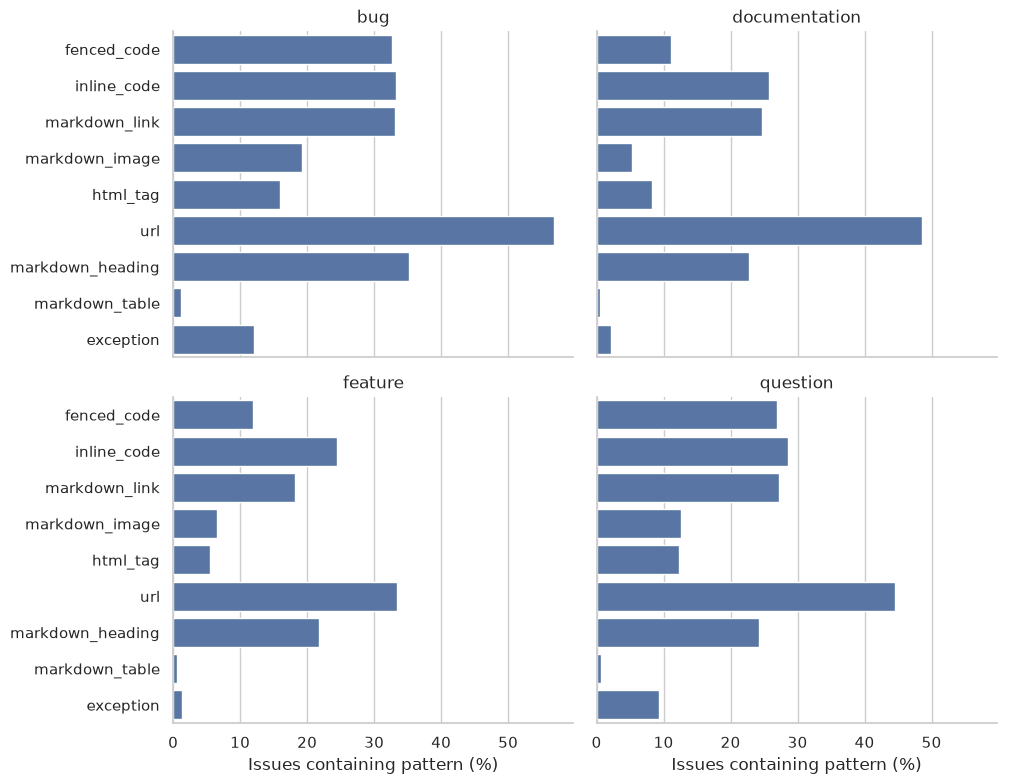

In [5]:
plot_data = structure_summary.reset_index().melt(
    id_vars="labels", var_name="structure", value_name="percentage"
)

plot_data["structure"] = plot_data["structure"].str.removeprefix("has_")

chart = sns.catplot(
    data=plot_data,
    x="percentage",
    y="structure",
    col="labels",
    kind="bar",
    col_wrap=2,
    height=4,
    aspect=1.3,
    sharex=True,
)

chart.set_axis_labels("Issues containing pattern (%)", "")
chart.set_titles("{col_name}")

## 4. Inspect Representative Examples

Review raw issue bodies containing each structural pattern.

Pay particular attention to:

- Whether code blocks contain diagnostic information.
- Whether URLs identify meaningful resources or are incidental.
- Whether Markdown and HTML formatting carry useful context.
- Whether exception messages and stack traces help identify the issue intent.

The examples are selected from the training sample only.

In [6]:
def inspect_examples(
    data: pd.DataFrame,
    pattern_name: str,
    n: int = 3,
    random_state: int = 42,
) -> None:
    """Display raw issues containing a selected structural pattern.

    Args:
        data: DataFrame containing issue titles, bodies, and pattern flags.
        pattern_name: Name of a pattern defined in PATTERNS.
        n: Maximum number of examples to display.
        random_state: Random seed for reproducible sampling.

    Raises:
        ValueError: If the requested pattern or sample size is invalid.
    """
    column = f"has_{pattern_name}"

    if column not in data.columns:
        raise ValueError(f"Unknown pattern: {pattern_name}")

    if n <= 0:
        raise ValueError("n must be positive")

    matches = data.loc[data[column]]

    if matches.empty:
        print(f"No examples found for {pattern_name}")
        return

    examples = matches.sample(
        n=min(n, len(matches)),
        random_state=random_state,
    )

    for index, row in examples.iterrows():
        print("=" * 80)
        print(f"Index: {index}")
        print(f"Label: {row['labels']}")
        print(f"Title: {row['title']}")
        print(f"Body length: {len(row['body']):,}")
        print("-" * 80)
        print(row["body"])
        print()

In [7]:
inspect_examples(sample, "fenced_code", n=3)

Index: 29580
Label: feature
Title: Add IDL padding calculator
Body length: 816
--------------------------------------------------------------------------------
For example, if we want to add a memcmp filter to Solana RPC JSON API calls like getProgramAccounts of this:
```rust
pub struct UserStakingState {
    pub version: u8,
    pub user_id: u64,
    pub staking_pool_state: Pubkey,
    pub owner: Pubkey,

    // User data to account for rewards
    pub user_stake: u64,
    pub rewards_tally: u128,

    pub _padding: [u64; 10],
}
```

we need to manually calculate each property (u8=1 bytes, u64=8 bytes, etc..) and then use a magic number in our code, the magic number will also be incorrect if the order of the struct properties ever changes

We should add an automatic IDL calculator that goes through the Anchor generated JSON IDL file and finds the account and property you're trying to filter by and returns the byte offset you need to filter by.

Index: 2908
Label: bug
Title: SVGs not s

In [8]:
inspect_examples(sample, "exception", n=3)

Index: 28483
Label: bug
Title: PrismicPreviewProvider in gatsby-ssr.js causes builds to fail in Gatsby V4
Body length: 5,024
--------------------------------------------------------------------------------
I'm updating my Prismic plugins to v5 as described in the [migration guide](https://prismic.io/docs/technologies/gatsby-prismic-v4-to-v5#update-gatsby). After following all the steps in the guide my builds are now failing. With some debugging I've narrowed down the cause of failures to the use of `<PrismicPreviewProvider>` component in my `gatsby-ssr.js` file. When commenting out this component, the builds succeed. However, previews hang and no longer work, so this isn't a viable solution/fix. 

I've tried passing the new `repositoryConfigs` props to the provider component but this doesn't seem to help. 

### Versions
- gatsby: v4
- gatsby-source-prismic: v5.2.3 <!-- ex: v5.2.3 -->
- gatsby-plugin-prismic-previews: 5.2.1 <!-- (if used) ex: v0.1.0 -->
- node: v14.18.1<!-- ex: v12.14.0

In [9]:
inspect_examples(sample, "html_tag", n=3)

Index: 36956
Label: feature
Title: [Perf] Changes at 1/5/2022 2:20:03 AM
Body length: 4,189
--------------------------------------------------------------------------------
### Run Information

Architecture | arm64
-- | --
OS | Windows 10.0.19041
Baseline | [ae2e360936eb0ee737fb81c872c87dd7794782d3](https://github.com/dotnet/runtime/commit/ae2e360936eb0ee737fb81c872c87dd7794782d3)
Compare | [cab2fd80cc2e3510cfd59db73406dfe9e4d859fc](https://github.com/dotnet/runtime/commit/cab2fd80cc2e3510cfd59db73406dfe9e4d859fc)
Diff | [Diff](https://github.com/dotnet/runtime/compare/ae2e360936eb0ee737fb81c872c87dd7794782d3...cab2fd80cc2e3510cfd59db73406dfe9e4d859fc)


### Improvements in PerfLabTests.CastingPerf

Benchmark | Baseline | Test | Test/Base | Test Quality | Edge Detector | Baseline IR | Compare IR | IR Ratio | Baseline ETL | Compare ETL
-- | -- | -- | -- | -- | -- | -- | -- | -- | -- | --
[IFooObjIsDescendantOfIFoo - Duration of single invocation](<https://pvscmdupload.blob.core.windows.

In [10]:
inspect_examples(sample, "markdown_link", n=3)

Index: 10008
Label: documentation
Title: learn pytoneo
Body length: 108
--------------------------------------------------------------------------------
- [py2neo-quickstart](https://github.com/elena/py2neo-quickstart)
- [docs](https://py2neo.org/v4/index.html)

Index: 3181
Label: bug
Title: Do not assume that multidb is multisite
Body length: 337
--------------------------------------------------------------------------------
E.g., I have an application with one site, default. On ACE, there are two databases: the default one and a migrate one. ACLI provides this prompt:

![image](https://user-images.githubusercontent.com/539205/129293868-cc015bb6-505a-4bf2-86ca-c37182de1e05.png)

This is wrong. It should only show 'default' since there is only one site.

Index: 41653
Label: bug
Title: [BUG] assets-v0 zip 
Body length: 644
--------------------------------------------------------------------------------
### Describe the bug

![Screenshot_20220406_210839](https://user-images.githubuserco

## 5. Inspect Long-Body Outliers

Identify the longest raw issue bodies in the sample and inspect their structure.

Determine whether excessive length comes from repeated logs, large code blocks, stack traces, embedded content, or genuinely detailed descriptions.

This is a preliminary sample-based audit. Maximum lengths and tail statistics must later be computed on the complete training split.

In [11]:
longest = sample.nlargest(10, "body_length")

display(longest[["labels", "title", "body_length", *structure_columns]])

,labels,title,body_length,has_fenced_code,has_inline_code,has_markdown_link,has_markdown_image,has_html_tag,has_url,has_markdown_heading,has_markdown_table,has_exception
16565,bug,"Connection got disposed (randomly, on x64 Windows 11)",231386,True,True,False,False,True,False,False,False,False
10672,question,"charger out of sync: expected enabled, got disabled // Easee Wallbox",210875,False,False,False,False,True,True,False,False,False
17248,bug,All docker jobs stalled and not restarting after update from 1.3.2 to 1.3.3,210786,True,False,False,False,False,True,True,False,False
35599,bug,[Issue]: LiveTV Hardware Transcoding Pixelated Video with Standard definition,177412,True,False,True,True,False,True,True,False,False
19944,bug,chip app segfaults while trying to run Test_TC_DM_1_3_Simulated test case,148298,True,False,False,False,True,True,True,False,True
36420,bug,Error: unable to verify the first certificate,142234,True,True,True,True,True,True,False,False,True
13940,feature,SQL Server - DBUP,135706,True,False,False,False,False,False,False,False,False
38868,bug,Seeing crash reports - `Signal 6 was raised (null)`,106398,True,True,True,True,True,True,True,False,True
3161,bug,Unable to start API,94492,True,True,True,False,True,True,True,False,True
16485,bug,Can not set 125 Hz/250Hz rates on Logitech MX518,91202,True,True,False,False,True,True,False,False,False


In [12]:
longest_index = longest.index[0]

print(f"Label: {sample.loc[longest_index, 'labels']}")
print(f"Title: {sample.loc[longest_index, 'title']}")
print(f"Length: {sample.loc[longest_index, 'body_length']:,}")
print(sample.loc[longest_index, "body"])

Label: bug
Title: Connection got disposed (randomly, on x64 Windows 11)
Length: 231,386
Bug type: Language Service

- OS and Version: Windows 11
- VS Code Version: 1.63.2
- C/C++ Extension Version: 1.8.3
- Other C++ extensions you installed:
  - `cschlosser.doxdocgen`
  - `jeff-hykin.better-cpp-syntax`
  - `ms-vscode.cmake-tools`
  - `ms-vscode.cpptools-themes`
  - `twxs.cmake`
- The workspace: A single, small project.

**Code sample and logs**
- Configurations in `c_cpp_properties.json`
  - None, I think.
  - My `settings.json` has `files.associations` set to:
    - "*.cpp": "cpp"
    - "*.dpp": "cpp"
    - "*.hpp": "cpp"
    - "*.ipp": "cpp"
    - "*.tpp": "cpp"

- Logs from running `C/C++: Log Diagnostics` from the VS Code command palette
```
-------- Diagnostics - 02/02/2022, 02:57:47
Version: 1.8.3
Current Configuration:
{
    "name": "Win32",
    "includePath": [
        "${workspaceFolder}/**"
    ],
    "defines": [
        "_DEBUG",
        "UNICODE",
        "_UNICODE"
    ],


## Findings — Structured Text Audit

### 1. Dataset and Body Length Distribution

The analysis was conducted on a stratified sample of **50,000 training issues**, preserving the original class distribution.

| Statistic | Body length (characters) |
|---|---:|
| Mean | 1,230 |
| Median | 502 |
| 90th percentile | 2,314 |
| 95th percentile | 3,956 |
| 99th percentile | 12,671 |
| Maximum | 231,386 |

**Key observations:**

- Body lengths are strongly right-skewed, with a relatively small number of extremely long issues.
- Most issues contain substantially less text than the longest examples.
- The maximum length is not representative of typical issues.
- Long bodies may contain useful descriptions, code, diagnostic information, or substantial repetition.

**Implication:** Arbitrary character-based truncation is not an appropriate default preprocessing strategy. Text length should be reassessed after cleaning before deciding whether additional length-control techniques are necessary.

### 2. Structured Content Patterns

GitHub issue bodies contain a mixture of natural language, Markdown formatting, code, logs, URLs, and diagnostic information.

| Pattern | Bug | Documentation | Feature | Question |
|---|---:|---:|---:|---:|
| Fenced code blocks | 32.67% | 11.17% | 11.85% | 26.88% |
| Inline code | 33.19% | 25.74% | 24.45% | 28.55% |
| Markdown links | 33.16% | 24.71% | 18.19% | 27.27% |
| Markdown images | 19.16% | 5.34% | 6.53% | 12.64% |
| HTML tags | 15.95% | 8.30% | 5.47% | 12.31% |
| URLs | 56.90% | 48.57% | 33.38% | 44.60% |
| Markdown headings | 35.25% | 22.74% | 21.77% | 24.25% |
| Markdown tables | 1.20% | 0.58% | 0.53% | 0.59% |
| Exception patterns | 12.00% | 2.15% | 1.34% | 9.29% |

These percentages represent the proportion of issues containing each detected pattern. Pattern detection is heuristic and does not guarantee complete Markdown or code parsing.

**Key observations:**

- Bug reports have the highest prevalence of fenced code blocks and exception patterns.
- Questions also frequently contain code and diagnostic information.
- URLs, Markdown links, and headings appear across all four classes.
- Structured content is potentially informative, rather than uniformly irrelevant noise.

**Implication:** Removing all code, URLs, or Markdown-associated content could discard useful classification signals.

### 3. Qualitative Inspection

Manual inspection revealed several important cases:

- **Feature requests:** Code snippets may explain proposed APIs, data structures, or required behavior. For example, the IDL padding calculator request includes a Rust structure that provides context for the proposed feature.
- **Bug reports:** Stack traces, exception names, and error messages can directly describe the reported failure.
- **Issue templates:** HTML comments and repetitive template instructions may introduce formatting noise without contributing to the actual report.
- **Image-heavy issues:** Some reports rely heavily on screenshots, with limited accompanying text. Image alt text may be worth preserving.
- **Performance reports:** Long bodies may contain benchmark tables, generated reports, links, and payloads rather than conventional prose.

These examples indicate that preprocessing should distinguish between formatting, diagnostic content, and potentially redundant information.

### 4. Extreme-Length Issues and Repeated Logs

The longest sampled issue, **"Connection got disposed (randomly, on x64 Windows 11)"**, contains 231,386 characters.

Inspection of the supplied issue text revealed extensive repetition of diagnostic messages and stack traces.

The message `Error: Connection got disposed.` appeared 139 times, associated with repeated failures involving requests such as `signatureHelp`, `documentHighlight`, and `completion`.

**Key observations:**

- Extreme text length can result from repeated diagnostic output rather than entirely unique information.
- Repeated stack frames can contribute substantially to text length.
- Exception types, distinct failure messages, and request names remain potentially valuable.
- Removing repeated lines indiscriminately may erase useful frequency or sequence information.

**Implication:** Repeated-log compression is a reasonable candidate for a separate preprocessing ablation, but should not be introduced as an unvalidated default.

### 5. Initial Preprocessing Decisions

The first preprocessing implementation will prioritize **semantic preservation** rather than maximum text reduction.

| Component | Initial approach |
|---|---|
| Markdown headings | Remove heading markers while preserving heading text |
| HTML comments | Remove as an initial cleaning hypothesis |
| Markdown links | Preserve visible anchor text |
| Markdown images | Preserve available alt text |
| Inline code | Remove delimiters while preserving content |
| Fenced code | Preserve content while removing supported delimiters |
| Exceptions and stack traces | Preserve diagnostic information |
| Whitespace | Normalize redundant whitespace |
| Repeated logs | Defer to a separate ablation |
| Truncation | Do not apply during preprocessing |

These are **initial design choices, not validated improvements**. Regex-based normalization has limitations, including complex Markdown syntax and potentially meaningful code indentation.

### 6. Next Steps

1. Validate the preprocessing functions with unit tests and representative before/after examples.
2. Apply preprocessing to the training data without modifying the original processed CSV files.
3. Recalculate body-length statistics after cleaning, including the maximum and upper percentiles.
4. Inspect the longest remaining issues and measure how much text was removed.
5. Evaluate the impact of preprocessing on classification performance using a controlled comparison against the raw-text baseline.
6. Consider repeated-log compression only if the remaining evidence supports it.

### Conclusion

The audit demonstrates that GitHub issue bodies contain substantial structured and diagnostic information. Some extreme-length issues also contain extensive repetition.

The preprocessing strategy will therefore focus on removing unnecessary formatting while retaining meaningful natural language, code, and diagnostic content.

**The effectiveness of each transformation must be established through qualitative validation and controlled model experiments, not assumed from shorter text alone.**


---


## 7. Preprocessing Validation — Before/After Inspection

Evaluate the initial minimal preprocessing implementation on representative training issues.

The objective is to inspect whether formatting noise is reduced without losing important semantic information.

This analysis is qualitative and does not establish predictive improvement.

The raw text remains unchanged, and no truncation is applied.


In [13]:
from src.preprocessing.text import preprocess_text

In [14]:
def compare_preprocessing(
    data: pd.DataFrame,
    index: int,
) -> None:
    """Compare raw and preprocessed text for a selected issue.

    Args:
        data: DataFrame containing issue bodies and labels.
        index: Index of the issue to inspect.
    """
    row = data.loc[index]

    raw = row["body"]
    cleaned = preprocess_text(raw)

    print(f"Label: {row['labels']}")
    print(f"Title: {row['title']}")
    print(f"Raw length: {len(raw):,}")
    print(f"Cleaned length: {len(cleaned):,}")
    print(f"Reduction: {(1 - len(cleaned) / max(len(raw), 1)) * 100:.2f}%")

    print("\n" + "=" * 30 + " RAW " + "=" * 30)
    print(raw)

    print("\n" + "=" * 28 + " CLEANED " + "=" * 28)
    print(cleaned)

In [15]:
compare_preprocessing(sample, 2908)

Label: bug
Title: SVGs not supported by PDF library
Raw length: 3,370
Cleaned length: 3,027
Reduction: 10.18%

============================== RAW ==============================
### Describe the Bug
<!-- A clear and concise description of what the bug is. -->
At the moment, we use svg images as icons and the media export from wordpress also might contain svg images.
These images are not included in PDFs which are generated with xhtml2pdf.
The corresponding issue is: https://github.com/xhtml2pdf/xhtml2pdf/issues/73
Apparently, there is an open PR for it (https://github.com/xhtml2pdf/xhtml2pdf/pull/561), but it shows no recent activity.

As solution, I see 3 options:
1. Change our icons to png and convert all svgs to pngs during the media export
2. See what's holding up the upstream process and try support the library maintainers
3. Switch to another PDF library

### Steps to Reproduce

1. Insert SVG into page
2. Convert this page to PDF
3. The image is missing in the PDF

### Expected Be

In [16]:
compare_preprocessing(sample, 29580)

Label: feature
Title: Add IDL padding calculator
Raw length: 816
Cleaned length: 798
Reduction: 2.21%

============================== RAW ==============================
For example, if we want to add a memcmp filter to Solana RPC JSON API calls like getProgramAccounts of this:
```rust
pub struct UserStakingState {
    pub version: u8,
    pub user_id: u64,
    pub staking_pool_state: Pubkey,
    pub owner: Pubkey,

    // User data to account for rewards
    pub user_stake: u64,
    pub rewards_tally: u128,

    pub _padding: [u64; 10],
}
```

we need to manually calculate each property (u8=1 bytes, u64=8 bytes, etc..) and then use a magic number in our code, the magic number will also be incorrect if the order of the struct properties ever changes

We should add an automatic IDL calculator that goes through the Anchor generated JSON IDL file and finds the account and property you're trying to filter by and returns the byte offset you need to filter by.

============================ CL

In [17]:
compare_preprocessing(sample, 48327)

Label: bug
Title: Removing a extension from workspace recommendations when missing case sensitivity
Raw length: 2,593
Cleaned length: 1,618
Reduction: 37.60%

============================== RAW ==============================
<!-- ⚠️⚠️ Do Not Delete This! bug_report_template ⚠️⚠️ -->
<!-- Please read our Rules of Conduct: https://opensource.microsoft.com/codeofconduct/ -->
<!-- 🕮 Read our guide about submitting issues: https://github.com/microsoft/vscode/wiki/Submitting-Bugs-and-Suggestions -->
<!-- 🔎 Search existing issues to avoid creating duplicates. -->
<!-- 🧪 Test using the latest Insiders build to see if your issue has already been fixed: https://code.visualstudio.com/insiders/ -->
<!-- 💡 Instead of creating your report here, use 'Report Issue' from the 'Help' menu in VS Code to pre-fill useful information. -->
<!-- 🔧 Launch with `code --disable-extensions` to check. -->
Does this issue occur when all extensions are disabled?: Yes

<!-- 🪓 If you answered No above, use 'Help: Start

In [18]:
compare_preprocessing(sample, 36956)

Label: feature
Title: [Perf] Changes at 1/5/2022 2:20:03 AM
Raw length: 4,189
Cleaned length: 4,130
Reduction: 1.41%

============================== RAW ==============================
### Run Information

Architecture | arm64
-- | --
OS | Windows 10.0.19041
Baseline | [ae2e360936eb0ee737fb81c872c87dd7794782d3](https://github.com/dotnet/runtime/commit/ae2e360936eb0ee737fb81c872c87dd7794782d3)
Compare | [cab2fd80cc2e3510cfd59db73406dfe9e4d859fc](https://github.com/dotnet/runtime/commit/cab2fd80cc2e3510cfd59db73406dfe9e4d859fc)
Diff | [Diff](https://github.com/dotnet/runtime/compare/ae2e360936eb0ee737fb81c872c87dd7794782d3...cab2fd80cc2e3510cfd59db73406dfe9e4d859fc)


### Improvements in PerfLabTests.CastingPerf

Benchmark | Baseline | Test | Test/Base | Test Quality | Edge Detector | Baseline IR | Compare IR | IR Ratio | Baseline ETL | Compare ETL
-- | -- | -- | -- | -- | -- | -- | -- | -- | -- | --
[IFooObjIsDescendantOfIFoo - Duration of single invocation](<https://pvscmdupload.blob.co

In [19]:
sample["cleaned_body"] = sample["body"].map(preprocess_text)
sample["cleaned_length"] = sample["cleaned_body"].str.len()

sample["length_reduction_pct"] = (
    (sample["body_length"] - sample["cleaned_length"])
    / sample["body_length"].replace(0, np.nan)
    * 100
)

length_comparison = pd.DataFrame(
    {
        "Raw": sample["body_length"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]),
        "Cleaned": sample["cleaned_length"].describe(
            percentiles=[0.5, 0.9, 0.95, 0.99]
        ),
    }
)

display(length_comparison)

print(
    "Changed issues:",
    (sample["body"] != sample["cleaned_body"]).sum(),
)

print(
    "Average length reduction:",
    f"{sample['length_reduction_pct'].mean():.2f}%",
)

,Raw,Cleaned
count,50000.000000,50000.000000
mean,1230.068320,1181.810060
std,3969.651053,3910.308676
min,0.000000,0.000000
50%,502.000000,483.000000
90%,2314.100000,2187.100000
95%,3956.000000,3760.050000
99%,12671.430000,12374.070000
max,231386.000000,229034.000000


Changed issues: 38957
Average length reduction: 3.25%


In [20]:
display(
    sample.nlargest(10, "cleaned_length")[
        ["labels", "title", "body_length", "cleaned_length", "length_reduction_pct"]
    ]
)

,labels,title,body_length,cleaned_length,length_reduction_pct
16565,bug,"Connection got disposed (randomly, on x64 Windows 11)",231386,229034,1.016483
17248,bug,All docker jobs stalled and not restarting after update from 1.3.2 to 1.3.3,210786,209874,0.432666
10672,question,"charger out of sync: expected enabled, got disabled // Easee Wallbox",210875,208739,1.012922
35599,bug,[Issue]: LiveTV Hardware Transcoding Pixelated Video with Standard definition,177412,175760,0.931166
19944,bug,chip app segfaults while trying to run Test_TC_DM_1_3_Simulated test case,148298,146585,1.155107
36420,bug,Error: unable to verify the first certificate,142234,141258,0.686193
13940,feature,SQL Server - DBUP,135706,135674,0.023580
38868,bug,Seeing crash reports - `Signal 6 was raised (null)`,106398,105357,0.978402
3161,bug,Unable to start API,94492,93412,1.142954
16485,bug,Can not set 125 Hz/250Hz rates on Logitech MX518,91202,89833,1.501064


In [21]:
sample["minimal_body"] = sample["body"].map(preprocess_text)
sample["minimal_length"] = sample["minimal_body"].str.len()

minimal_comparison = pd.DataFrame(
    {
        "Raw": sample["body_length"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]),
        "Minimal": sample["minimal_length"].describe(
            percentiles=[0.5, 0.9, 0.95, 0.99]
        ),
    }
)

display(minimal_comparison)

print(
    "Changed issues:",
    (sample["body"] != sample["minimal_body"]).sum(),
)

print(
    "Total character reduction:",
    f"{(1 - sample['minimal_length'].sum() / sample['body_length'].sum()) * 100:.2f}%",
)

,Raw,Minimal
count,50000.000000,50000.000000
mean,1230.068320,1181.810060
std,3969.651053,3910.308676
min,0.000000,0.000000
50%,502.000000,483.000000
90%,2314.100000,2187.100000
95%,3956.000000,3760.050000
99%,12671.430000,12374.070000
max,231386.000000,229034.000000


Changed issues: 38957
Total character reduction: 3.92%


In [22]:
display(
    sample.nlargest(10, "minimal_length")[
        ["labels", "title", "body_length", "minimal_length"]
    ]
)

,labels,title,body_length,minimal_length
16565,bug,"Connection got disposed (randomly, on x64 Windows 11)",231386,229034
17248,bug,All docker jobs stalled and not restarting after update from 1.3.2 to 1.3.3,210786,209874
10672,question,"charger out of sync: expected enabled, got disabled // Easee Wallbox",210875,208739
35599,bug,[Issue]: LiveTV Hardware Transcoding Pixelated Video with Standard definition,177412,175760
19944,bug,chip app segfaults while trying to run Test_TC_DM_1_3_Simulated test case,148298,146585
36420,bug,Error: unable to verify the first certificate,142234,141258
13940,feature,SQL Server - DBUP,135706,135674
38868,bug,Seeing crash reports - `Signal 6 was raised (null)`,106398,105357
3161,bug,Unable to start API,94492,93412
16485,bug,Can not set 125 Hz/250Hz rates on Logitech MX518,91202,89833



## 8. Long-Body Diagnostics

The previous preprocessing experiments showed that conservative normalization reduces formatting noise but has limited impact on extremely long issue bodies.

This section investigates whether long bodies are dominated by repeated lines, unique diagnostic information, code, or generated reports.

The goal is to identify preprocessing opportunities without applying arbitrary truncation or deleting potentially useful content.

All measurements are exploratory and use the existing stratified training sample.


In [23]:
def analyze_line_repetition(text: str) -> dict:
    """Measure repeated non-empty lines in an issue body.

    Args:
        text: Issue body.

    Returns:
        dict: Line counts and repetition statistics.
    """
    lines = [line.strip() for line in text.splitlines() if line.strip()]

    total = len(lines)
    unique = len(set(lines))

    return {
        "total_lines": total,
        "unique_lines": unique,
        "repeated_lines": total - unique,
        "repetition_ratio": ((total - unique) / total if total else 0.0),
    }

In [24]:
longest_issues = sample.nlargest(100, "body_length").copy()

line_stats = longest_issues["body"].apply(analyze_line_repetition)
line_stats = pd.DataFrame(line_stats.tolist(), index=longest_issues.index)

longest_issues = longest_issues.join(line_stats)

display(
    longest_issues[
        [
            "labels",
            "title",
            "body_length",
            "total_lines",
            "unique_lines",
            "repeated_lines",
            "repetition_ratio",
        ]
    ]
    .sort_values("repetition_ratio", ascending=False)
    .head(20)
)

,labels,title,body_length,total_lines,unique_lines,repeated_lines,repetition_ratio
16565,bug,"Connection got disposed (randomly, on x64 Windows 11)",231386,2347,99,2248,0.957818
3817,bug,Quarkus org.graalvm.nativeimage.svm IllegalArgumentException: Unsupported api 524288 ClassVisitor Gizmo,57725,695,123,572,0.823022
26868,bug,[BUG] Memory leak in shuffle read,41183,425,91,334,0.785882
27597,feature,[Perf] Windows 10.0.18362/x64 : Improvement on 8/13/2022 7:28:42 AM,42841,1101,290,811,0.736603
28955,bug,Midea-discover an error occurred,43285,388,104,284,0.731959
27150,bug,🐞 Bug report:,52303,671,182,489,0.728763
38368,feature,[Perf] Changes at 6/20/2022 11:14:52 PM,51249,494,135,359,0.726721
20247,bug,Nbt Crash Forge 1.12.2,60147,652,183,469,0.719325
25235,bug,http.rb receiving empty response when pivoting (scanner/http/tomcat_mgr_login),64946,686,195,491,0.715743
21164,feature,[Perf] ubuntu 18.04/x64 : Improvement on 8/4/2022 11:58:08 PM,57506,532,152,380,0.714286



### Long-Body Diagnostics — Findings

We analyzed the 100 longest issue bodies in the 50,000-row stratified training sample to investigate repeated content.

**Key observations:**

- Several extremely long issues contain substantial line repetition.
- The longest issue, "Connection got disposed (randomly, on x64 Windows 11)", contains 2,347 non-empty lines but only 99 unique stripped lines, resulting in a repetition ratio of 95.78%.
- Other bug reports contain repeated stack traces, error messages, and diagnostic output.
- Multiple feature-labeled performance reports also exhibit high repetition ratios, suggesting that generated benchmark reports contribute to long-body redundancy.
- Repetition is not limited to a single issue class or document structure.

**Interpretation:**

The results suggest that repeated diagnostic content contributes substantially to the long-body problem. However, the repetition ratio counts identical lines regardless of their positions and does not establish whether those lines can be safely removed.

**Next steps:**

1. Inspect representative high-repetition and low-repetition issues.
2. Distinguish consecutive log repetition from recurring but potentially meaningful content.
3. Design a conservative log-compression strategy.
4. Evaluate compression as a separate preprocessing ablation against the raw baseline.

No log compression or additional truncation was applied during this analysis.


---


## 9. Repeated-Line Content Inspection

The long-body diagnostics revealed substantial line repetition in several issues, including bug reports and generated performance reports.

This section examines the most frequently repeated lines and distinguishes consecutive repetition from non-consecutive recurrence.

The objective is to determine whether repeated content can be compressed without removing useful diagnostic information.

No text transformation is applied in this section.


In [25]:
from collections import Counter


def inspect_repeated_lines(
    text: str,
    top_n: int = 15,
) -> pd.DataFrame:
    """Identify the most frequently repeated non-empty lines."""
    lines = [line.strip() for line in text.splitlines() if line.strip()]

    counts = Counter(lines)

    return pd.DataFrame(
        [
            {
                "line": line[:200],
                "count": count,
            }
            for line, count in counts.most_common(top_n)
        ]
    )

In [26]:
display(
    inspect_repeated_lines(
        sample.loc[16565, "body"],
        top_n=20,
    )
)

,line,count
0,at CallbackList.invoke (c:\Users\<my_user_name>\.vscode\extensions\ms-vscode.cpptools-1.8.3\dist\main.js:46441:39),278
1,at Emitter.fire (c:\Users\<my_user_name>\.vscode\extensions\ms-vscode.cpptools-1.8.3\dist\main.js:46499:36),278
2,Error: Connection got disposed.,139
3,at Object.dispose (c:\Users\<my_user_name>\.vscode\extensions\ms-vscode.cpptools-1.8.3\dist\main.js:47723:25),139
4,at Object.dispose (c:\Users\<my_user_name>\.vscode\extensions\ms-vscode.cpptools-1.8.3\dist\main.js:48643:35),139
5,at LanguageClient.handleConnectionClosed (c:\Users\<my_user_name>\.vscode\extensions\ms-vscode.cpptools-1.8.3\dist\main.js:50725:42),139
6,at LanguageClient.handleConnectionClosed (c:\Users\<my_user_name>\.vscode\extensions\ms-vscode.cpptools-1.8.3\dist\main.js:51915:15),139
7,at closeHandler (c:\Users\<my_user_name>\.vscode\extensions\ms-vscode.cpptools-1.8.3\dist\main.js:50712:18),139
8,at closeHandler (c:\Users\<my_user_name>\.vscode\extensions\ms-vscode.cpptools-1.8.3\dist\main.js:47073:26),139
9,at StreamMessageReader.fireClose (c:\Users\<my_user_name>\.vscode\extensions\ms-vscode.cpptools-1.8.3\dist\main.js:47889:27),139


In [27]:
display(
    inspect_repeated_lines(
        sample.loc[27597, "body"],
        top_n=20,
    )
)

,line,count
0,"mov [rsp+38],rdi",32
1,"mov [rsp+40],ebx",32
2,"mov [rsp+28],rbp",32
3,"mov [rsp+30],r14d",32
4,"lea rcx,[rsp+38]",32
5,"lea rdx,[rsp+28]",32
6,"mov r8d,esi",32
7,call qword ptr [0B4F8],32
8,"mov r15d,eax",30
9,"xor eax,r15d",28


In [ ]:
def consecutive_repetition_stats(text: str) -> dict:
    """Measure adjacent identical non-empty lines."""
    lines = [line.strip() for line in text.splitlines() if line.strip()]

    if not lines:
        return {
            "total_lines": 0,
            "consecutive_duplicates": 0,
            "consecutive_ratio": 0.0,
        }

    consecutive_duplicates = sum(
        current == previous
        for previous, current in zip(
            lines,
            lines[1:],
            strict=False,
        )
    )

    return {
        "total_lines": len(lines),
        "consecutive_duplicates": consecutive_duplicates,
        "consecutive_ratio": consecutive_duplicates / len(lines),
    }

In [29]:
consecutive_stats = longest_issues["body"].apply(consecutive_repetition_stats)

consecutive_stats = pd.DataFrame(
    consecutive_stats.tolist(),
    index=longest_issues.index,
)

display(
    longest_issues[["labels", "title", "body_length", "repetition_ratio"]]
    .join(consecutive_stats[["consecutive_duplicates", "consecutive_ratio"]])
    .sort_values("repetition_ratio", ascending=False)
    .head(20)
)

,labels,title,body_length,repetition_ratio,consecutive_duplicates,consecutive_ratio
16565,bug,"Connection got disposed (randomly, on x64 Windows 11)",231386,0.957818,1,0.000426
3817,bug,Quarkus org.graalvm.nativeimage.svm IllegalArgumentException: Unsupported api 524288 ClassVisitor Gizmo,57725,0.823022,0,0.000000
26868,bug,[BUG] Memory leak in shuffle read,41183,0.785882,1,0.002353
27597,feature,[Perf] Windows 10.0.18362/x64 : Improvement on 8/13/2022 7:28:42 AM,42841,0.736603,0,0.000000
28955,bug,Midea-discover an error occurred,43285,0.731959,0,0.000000
27150,bug,🐞 Bug report:,52303,0.728763,0,0.000000
38368,feature,[Perf] Changes at 6/20/2022 11:14:52 PM,51249,0.726721,0,0.000000
20247,bug,Nbt Crash Forge 1.12.2,60147,0.719325,0,0.000000
25235,bug,http.rb receiving empty response when pivoting (scanner/http/tomcat_mgr_login),64946,0.715743,0,0.000000
21164,feature,[Perf] ubuntu 18.04/x64 : Improvement on 8/4/2022 11:58:08 PM,57506,0.714286,0,0.000000



## 10. Repeated Block Analysis

Previous diagnostics showed that highly repetitive issue bodies often contain very few consecutive duplicate lines.

This suggests that repetition may occur at the sequence level rather than at the individual-line level.

We examine exact repeated sequences of five consecutive non-empty lines to identify repeated stack traces, diagnostic blocks, and generated report structures.

This analysis is exploratory. Repeated blocks are counted but not removed or compressed.


In [30]:
def repeated_block_stats(
    text: str,
    block_size: int = 5,
) -> dict:
    """Measure repeated sequences of consecutive non-empty lines.

    Args:
        text: Issue body.
        block_size: Number of lines per block.

    Returns:
        dict: Repeated block statistics.
    """
    if block_size < 1:
        raise ValueError("block_size must be positive")

    lines = [line.strip() for line in text.splitlines() if line.strip()]

    if len(lines) < block_size:
        return {
            "total_blocks": 0,
            "unique_blocks": 0,
            "repeated_blocks": 0,
            "block_repetition_ratio": 0.0,
        }

    blocks = [
        tuple(lines[i : i + block_size]) for i in range(len(lines) - block_size + 1)
    ]

    counts = Counter(blocks)

    total = len(blocks)
    unique = len(counts)

    return {
        "total_blocks": total,
        "unique_blocks": unique,
        "repeated_blocks": total - unique,
        "block_repetition_ratio": (total - unique) / total,
    }

In [31]:
block_stats = longest_issues["body"].apply(
    repeated_block_stats,
    block_size=5,
)

block_stats = pd.DataFrame(
    block_stats.tolist(),
    index=longest_issues.index,
)

block_analysis = longest_issues[
    ["labels", "title", "body_length", "repetition_ratio"]
].join(block_stats)

display(
    block_analysis.sort_values(
        "block_repetition_ratio",
        ascending=False,
    ).head(20)
)

,labels,title,body_length,repetition_ratio,total_blocks,unique_blocks,repeated_blocks,block_repetition_ratio
16565,bug,"Connection got disposed (randomly, on x64 Windows 11)",231386,0.957818,2343,127,2216,0.945796
3817,bug,Quarkus org.graalvm.nativeimage.svm IllegalArgumentException: Unsupported api 524288 ClassVisitor Gizmo,57725,0.823022,691,197,494,0.714906
20247,bug,Nbt Crash Forge 1.12.2,60147,0.719325,648,215,433,0.668210
25235,bug,http.rb receiving empty response when pivoting (scanner/http/tomcat_mgr_login),64946,0.715743,682,262,420,0.615836
27597,feature,[Perf] Windows 10.0.18362/x64 : Improvement on 8/13/2022 7:28:42 AM,42841,0.736603,1097,454,643,0.586144
41476,bug,Che 7.42.0 - Your Registry Is Invalid Message,45645,0.671717,590,248,342,0.579661
26868,bug,[BUG] Memory leak in shuffle read,41183,0.785882,421,177,244,0.579572
27150,bug,🐞 Bug report:,52303,0.728763,667,292,375,0.562219
6087,bug,[Bug]: No Telegram Message,57087,0.664592,1603,743,860,0.536494
41578,bug,Zammad UI should silently discard Cache / apply2file errors,48744,0.537757,433,214,219,0.505774


In [32]:
display(
    block_analysis[
        [
            "repetition_ratio",
            "block_repetition_ratio",
        ]
    ].describe()
)

,repetition_ratio,block_repetition_ratio
count,100.000000,100.000000
mean,0.309010,0.163013
std,0.277417,0.209761
min,0.000000,0.000000
25%,0.059822,0.000000
50%,0.213852,0.045099
75%,0.610440,0.308890
max,0.957818,0.945796



## 11. Block Repetition by Body Length

The longest issues show substantial variation in repeated five-line sequences. However, this subset is not representative of the full training distribution.

This section compares block repetition across body-length groups to determine whether repeated sequences are concentrated in unusually long issues or are also common in shorter reports.

We use a stratified sample by body-length category to limit computational cost.

The analysis is exploratory and does not modify issue text.


In [33]:
length_bins = [-1, 500, 2_000, 10_000, float("inf")]
length_labels = [
    "0–500",
    "501–2K",
    "2K–10K",
    ">10K",
]

sample["length_group"] = pd.cut(
    sample["body_length"],
    bins=length_bins,
    labels=length_labels,
)

display(sample["length_group"].value_counts().reindex(length_labels))

length_group
0–500     24948
501–2K    19085
2K–10K     5268
>10K        699
Name: count, dtype: int64

In [34]:
repetition_sample = (
    sample.groupby("length_group", observed=True)
    .apply(
        lambda group: group.sample(
            n=min(200, len(group)),
            random_state=42,
        ),
        include_groups=False,
    )
    .reset_index(drop=True)
)

In [35]:
repetition_sample = pd.concat(
    [
        group.sample(
            n=min(200, len(group)),
            random_state=42,
        )
        for _, group in sample.groupby(
            "length_group",
            observed=True,
        )
    ],
    ignore_index=True,
)

In [36]:
repetition_sample["block_repetition_ratio"] = (
    repetition_sample["body"]
    .apply(repeated_block_stats)
    .apply(lambda stats: stats["block_repetition_ratio"])
)

repetition_summary = (
    repetition_sample.groupby("length_group", observed=True)["block_repetition_ratio"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        max="max",
    )
    .reindex(length_labels)
)

display(repetition_summary)

,count,mean,median,max
length_group,,,,
0–500,200,0.000000,0.000000,0.000000
501–2K,200,0.001143,0.000000,0.090909
2K–10K,200,0.022482,0.000000,0.635294
>10K,200,0.093943,0.001946,0.807933


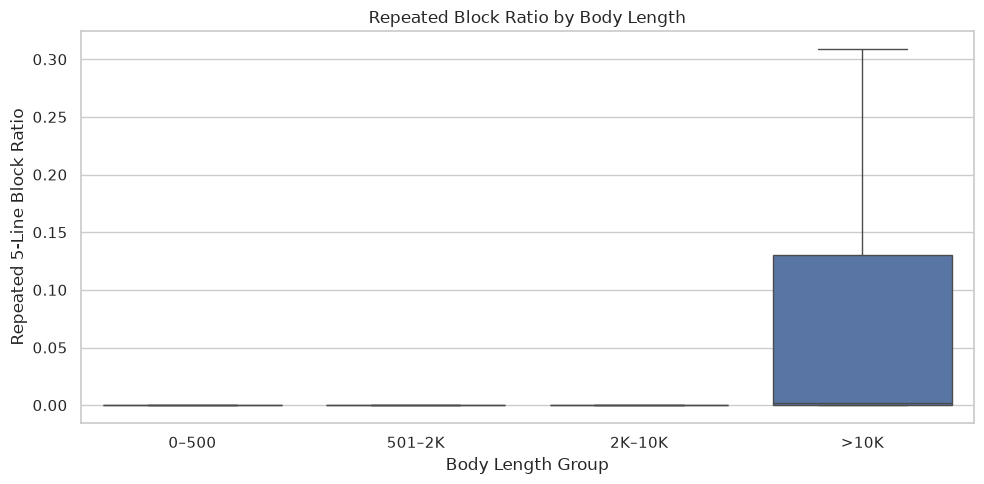

In [38]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=repetition_sample,
    x="length_group",
    y="block_repetition_ratio",
    order=length_labels,
    showfliers=False,
)

plt.title("Repeated Block Ratio by Body Length")
plt.xlabel("Body Length Group")
plt.ylabel("Repeated 5-Line Block Ratio")
plt.tight_layout()
plt.show()


## 12. Issue Template and Boilerplate Audit

This section examines common GitHub issue-template phrases and instructions that may appear in issue bodies.

The objective is to estimate the prevalence of template-related content and identify potential sources of shortcut learning.

We distinguish template instructions from useful structural headings, since headings such as "Expected Behavior" and "Steps to Reproduce" may carry meaningful information.

No boilerplate removal is applied during this analysis.


In [39]:
template_patterns = {
    "clear_concise_description": r"a clear and concise description",
    "steps_to_reproduce": r"steps to reproduce",
    "expected_behavior": r"expected behavio[u]?r",
    "actual_behavior": r"actual behavio[u]?r",
    "additional_context": r"additional context",
    "check_existing_issues": r"search existing issues",
    "code_of_conduct": r"code of conduct",
    "checklist": r"(?m)^\s*[-*]\s*\[[ xX]\]",
    "html_comment": r"<!--[\s\S]*?-->",
}

In [40]:
template_counts = pd.DataFrame(
    {
        name: (
            sample["body"]
            .str.contains(pattern, case=False, regex=True, na=False)
            .groupby(sample["labels"])
            .mean()
            .mul(100)
        )
        for name, pattern in template_patterns.items()
    }
).T

display(template_counts.round(2))

labels,bug,documentation,feature,question
clear_concise_description,2.48,0.67,1.34,0.95
steps_to_reproduce,24.84,2.65,1.20,5.55
expected_behavior,25.81,2.38,1.65,6.40
actual_behavior,6.53,0.63,0.40,1.51
additional_context,9.12,2.42,6.40,4.14
check_existing_issues,0.37,0.31,0.10,0.20
code_of_conduct,1.90,0.99,0.90,0.53
checklist,10.89,14.39,10.91,8.14
html_comment,8.25,5.87,4.28,6.73


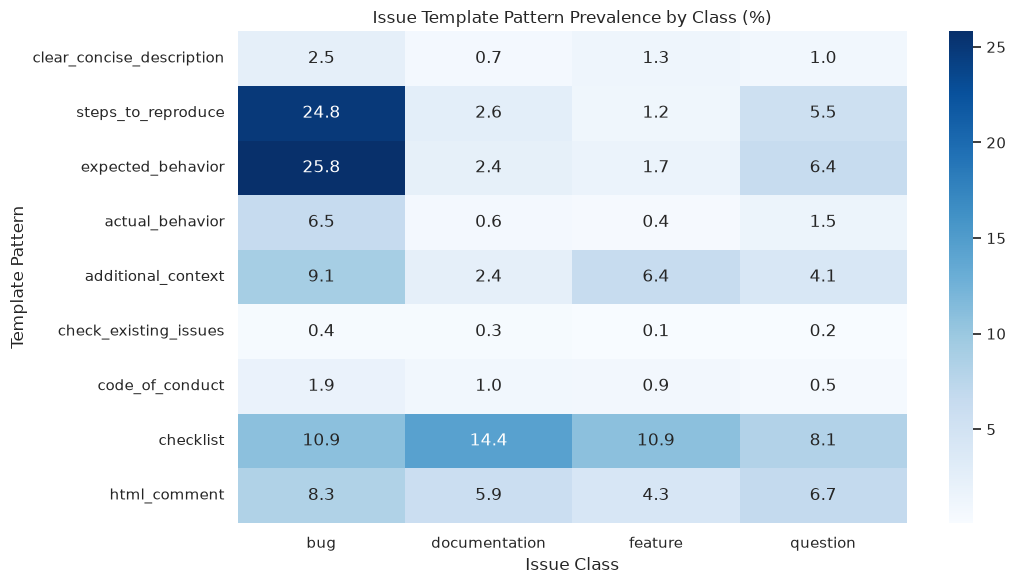

In [41]:
plt.figure(figsize=(11, 6))

sns.heatmap(
    template_counts,
    annot=True,
    fmt=".1f",
    cmap="Blues",
)

plt.title("Issue Template Pattern Prevalence by Class (%)")
plt.xlabel("Issue Class")
plt.ylabel("Template Pattern")
plt.tight_layout()
plt.show()


### Long-Body Analysis — Conclusion

Repeated content is concentrated in a subset of long issue bodies rather than being uniformly distributed across the dataset.

In the 50,000-issue sample, 88.07% of bodies contain at most 2,000 characters, while only 1.40% exceed 10,000 characters.

A length-stratified analysis of 800 issues found that median five-line block repetition was zero in the three shorter length groups and approximately 0.19% in the longest group.

A small number of long issues exhibit substantial repetition, including repeated stack traces, diagnostic logs, and benchmark reports.

**Decision:** Do not apply global line deduplication or automatic block compression. Preserve the raw text and revisit targeted long-body handling as a separate experiment if needed.


---


## 13. Unfilled Issue Template Inspection

The template-pattern audit found that structural headings such as "Steps to Reproduce" and "Expected Behavior" are strongly associated with bug reports.

However, these headings may represent useful issue-report structure rather than removable noise.

This section focuses on identifying unfilled template instructions, distinguishing instructions embedded in HTML comments from instructions appearing as visible text.

The goal is to identify conservative preprocessing candidates while preserving user-provided issue descriptions and diagnostic information.


In [42]:
instruction_patterns = {
    "clear_concise": r"a clear and concise description",
    "describe_problem": r"please describe (?:the|your) (?:problem|issue|bug)",
    "provide_steps": r"please provide (?:the )?steps",
    "add_screenshots": r"add screenshots",
    "delete_template": r"delete (?:this|the) template",
}

inspection_rows = []

for name, pattern in instruction_patterns.items():
    matches = sample["body"].str.contains(
        pattern,
        case=False,
        regex=True,
        na=False,
    )

    matched = sample.loc[matches, ["labels", "title", "body"]]

    inspection_rows.append(
        {
            "pattern": name,
            "count": len(matched),
            "percentage": len(matched) / len(sample) * 100,
        }
    )

instruction_summary = pd.DataFrame(inspection_rows)

display(instruction_summary)

,pattern,count,percentage
0,clear_concise,945,1.890
1,describe_problem,93,0.186
2,provide_steps,28,0.056
3,add_screenshots,655,1.310
4,delete_template,12,0.024


In [43]:
def extract_match_context(
    text: str,
    pattern: str,
    context_chars: int = 120,
) -> str:
    """Extract text surrounding the first regex match."""
    match = re.search(pattern, text, flags=re.IGNORECASE)

    if match is None:
        return ""

    start = max(0, match.start() - context_chars)
    end = min(len(text), match.end() + context_chars)

    return text[start:end].replace("\n", " ")


for name, pattern in instruction_patterns.items():
    matches = sample["body"].str.contains(
        pattern,
        case=False,
        regex=True,
        na=False,
    )

    examples = sample.loc[matches, ["labels", "title", "body"]].head(5)

    print(f"\n{name.upper()}")

    for _, row in examples.iterrows():
        print(f"Label: {row['labels']}")
        print(f"Title: {row['title']}")
        print(
            extract_match_context(
                row["body"],
                pattern,
            )
        )
        print("-" * 50)


CLEAR_CONCISE
Label: bug
Title: test
 2. Co to '...'duce the behavior:  on of what the bug is.
--------------------------------------------------
Label: bug
Title: [BUG] do you know why i get kicked when i have my delays at 0 and i get kicked from server when i cpvp
 2. Set the setting '...'ehavior:of what the bug is.
--------------------------------------------------
Label: bug
Title: Notebooks testing failing
e the behavior: 1. Go to '...' 2. Click on '....' 3. Scroll down to '....' 4. See error -->  ## Expected Behavior  <!-- A clear and concise description of what you expected to happen. -->  ## Additional Context  <!-- Add any other context about the problem here: - Pyboti
--------------------------------------------------
Label: feature
Title: Show the name of the request in the pane, not just in the tab. Also make the request being edited more distinctive in the requests list.
 I use descriptive names on my requests. These request may have the same url (E.g. they cha
----------

In [44]:
def inspect_pattern_matches(
    data: pd.DataFrame,
    pattern: str,
    n: int = 5,
    context_chars: int = 150,
) -> None:
    """Inspect exact regex matches with surrounding text."""
    matches = data["body"].str.contains(
        pattern,
        case=False,
        regex=True,
        na=False,
    )

    for _, row in data.loc[matches].head(n).iterrows():
        text = row["body"]
        match = re.search(pattern, text, flags=re.IGNORECASE)

        if match is None:
            continue

        start = max(0, match.start() - context_chars)
        end = min(len(text), match.end() + context_chars)

        print(f"Label: {row['labels']}")
        print(f"Title: {row['title']}")
        print(f"Exact match: {match.group(0)!r}")
        print(f"Context: {text[start:end]!r}")
        print("-" * 70)

In [45]:
inspect_pattern_matches(
    sample,
    instruction_patterns["clear_concise"],
    n=5,
)

inspect_pattern_matches(
    sample,
    instruction_patterns["add_screenshots"],
    n=5,
)

Label: bug
Title: test
Exact match: 'A clear and concise description'
Context: "**Describe the bug (Required)**  \r\ne.g. A clear and concise description of what the bug is.\r\n\r\n**To Reproduce (Required)**  \r\nSteps to reproduce the behavior:  \r\ne.g.   \r\n1. Go to '...'\r\n2. Click on '....'\r\n3. Scroll down"
----------------------------------------------------------------------
Label: bug
Title: [BUG] do you know why i get kicked when i have my delays at 0 and i get kicked from server when i cpvp
Exact match: 'A clear and concise description'
Context: "**Describe the bug**\r\nA clear and concise description of what the bug is.\r\n\r\n**To Reproduce**\r\nSteps to reproduce the behavior:\r\n1. Turn on module: '...'\r\n2. Set the setting to '....'\r\n3. See error\r\n\r\n**"
----------------------------------------------------------------------
Label: bug
Title: Notebooks testing failing
Exact match: 'A clear and concise description'
Context: "roduce\n\n<!-- Steps to reproduce the


## 14. Residual Template Noise After Minimal Preprocessing

Manual inspection confirmed that template instructions occur both inside HTML comments and as visible text.

This section measures how frequently selected instruction phrases remain after minimal preprocessing.

The goal is to distinguish already-removed HTML-comment instructions from residual visible placeholders, without automatically deleting legitimate issue content.

The results will guide whether a separate conservative template-cleaning ablation is justified.


In [48]:
from src.preprocessing.text import preprocess_text

residual_sample = sample[["labels", "title", "body"]].copy()

residual_sample["minimal_body"] = residual_sample["body"].map(preprocess_text)

residual_rows = []

for name, pattern in instruction_patterns.items():
    raw_matches = residual_sample["body"].str.contains(
        pattern,
        case=False,
        regex=True,
        na=False,
    )

    minimal_matches = residual_sample["minimal_body"].str.contains(
        pattern,
        case=False,
        regex=True,
        na=False,
    )

    residual_rows.append(
        {
            "pattern": name,
            "raw_count": int(raw_matches.sum()),
            "remaining_count": int(minimal_matches.sum()),
            "removed_count": int((raw_matches & ~minimal_matches).sum()),
            "remaining_pct": round(
                minimal_matches.mean() * 100,
                3,
            ),
        }
    )

residual_summary = pd.DataFrame(residual_rows)

display(residual_summary)

,pattern,raw_count,remaining_count,removed_count,remaining_pct
0,clear_concise,945,560,385,1.120
1,describe_problem,93,76,17,0.152
2,provide_steps,28,22,6,0.044
3,add_screenshots,655,466,189,0.932
4,delete_template,12,1,11,0.002


In [49]:
pattern = instruction_patterns["clear_concise"]

remaining = residual_sample[
    residual_sample["minimal_body"].str.contains(
        pattern,
        case=False,
        regex=True,
        na=False,
    )
]

display(remaining[["labels", "title"]].head(10))

for _, row in remaining.head(5).iterrows():
    print(f"\nLabel: {row['labels']}")
    print(f"Title: {row['title']}")
    print(
        extract_match_context(
            row["minimal_body"],
            pattern,
            context_chars=150,
        )
    )
    print("-" * 60)

,labels,title
47,bug,test
153,bug,[BUG] do you know why i get kicked when i have my delays at 0 and i get kicked from server when i cpvp
232,feature,Connect OSMNX to a local OSM databasae
411,bug,Can
614,feature,PICTURE PAWN LLC
627,bug,[management] HTTP2 is set by default when creating new groups
636,bug,BCO step numbers change to zero
715,bug,The tray icon's right-click menu does not close when the application is quitting
724,feature,Add `DictionaryArray::key` function
816,feature,[FeatureReq - Edge Addons site] Ability to report misconduct in user reviews on a Microsoft Edge Add-on product detail page



Label: bug
Title: test
**Describe the bug (Required)**   e.g. A clear and concise description of what the bug is.  **To Reproduce (Required)**   Steps to reproduce the behavior:   e.g.    1. Go to '...' 2. Click on '....' 3. Scroll down to '..
------------------------------------------------------------

Label: bug
Title: [BUG] do you know why i get kicked when i have my delays at 0 and i get kicked from server when i cpvp
**Describe the bug** A clear and concise description of what the bug is.  **To Reproduce** Steps to reproduce the behavior: 1. Turn on module: '...' 2. Set the setting to '....' 3. See error  **Expected
------------------------------------------------------------

Label: feature
Title: Connect OSMNX to a local OSM databasae
**Is your feature proposal related to a problem?** Maybe.   **A clear and concise description of what the problem is.** I need to connect OSMNX to my local OpenStreetMap server installed by ```overv/openstreetmap-tile-server``` Docker. I have 
--


## 15. Low-Information Issue Audit

The residual template inspection identified issue reports containing unfilled placeholders, sometimes alongside useful descriptions.

This section investigates potential low-information issues by combining weak-title indicators with residual template instructions.

The objective is to identify candidates for manual review, not to automatically exclude issues from training.

Weak titles and template phrases are heuristic signals only. Their presence does not establish that an issue is invalid or incorrectly labeled.


In [50]:
weak_title_pattern = (
    r"(?i)^\s*(?:"
    r"test|testing|bug|issue|help|question|"
    r"problem|error|feature|request|hi|hello"
    r")\s*[.!?]*\s*$"
)

quality_sample = residual_sample.copy()

quality_sample["weak_title"] = quality_sample["title"].str.contains(
    weak_title_pattern, regex=True, na=False
)

quality_sample["residual_template"] = False

for pattern in instruction_patterns.values():
    quality_sample["residual_template"] |= quality_sample["minimal_body"].str.contains(
        pattern,
        case=False,
        regex=True,
        na=False,
    )

quality_sample["review_candidate"] = (
    quality_sample["weak_title"] & quality_sample["residual_template"]
)

display(
    pd.DataFrame(
        {
            "signal": [
                "Weak title",
                "Residual template",
                "Both signals",
            ],
            "count": [
                int(quality_sample["weak_title"].sum()),
                int(quality_sample["residual_template"].sum()),
                int(quality_sample["review_candidate"].sum()),
            ],
        }
    )
)

,signal,count
0,Weak title,24
1,Residual template,937
2,Both signals,3


In [51]:
candidates = quality_sample.loc[
    quality_sample["review_candidate"],
    ["labels", "title", "minimal_body"],
]

print("Review candidates:", len(candidates))

for _, row in candidates.head(10).iterrows():
    print(f"\nLabel: {row['labels']}")
    print(f"Title: {row['title']}")
    print(f"Body preview: {row['minimal_body'][:600]!r}")
    print("-" * 70)

Review candidates: 3

Label: bug
Title: test
Body preview: "**Describe the bug (Required)**  \ne.g. A clear and concise description of what the bug is.\n\n**To Reproduce (Required)**  \nSteps to reproduce the behavior:  \ne.g.   \n1. Go to '...'\n2. Click on '....'\n3. Scroll down to '....'\n4. See error\n\n**Expected behavior**  \ne.g. A clear and concise description of what you expected to happen.\n\n**Error logs**  \ne.g. If applicable, add logs to help explain your problem.\n\n**Environment**  \n - OS: [e.g. iOS]\n - Version [e.g. 22]\n\n**Additional context**  \nex) Add any other context about the problem here.\n"
----------------------------------------------------------------------

Label: bug
Title: test
Body preview: "**Describe the bug**\nA clear and concise description of what the bug is.\n\n**To Reproduce**\n`com.mysql.jdbc.exceptions.jdbc4.MySQLSyntaxErrorException: You have an error in your SQL syntax; check the manual that corresponds to your MySQL server version for the